# Lab 16 — A team of VLAs

**Book sections:** [14.1](../../book/docs/chapters/14-multi-robot/dec-pomdp.md)–[14.4](../../book/docs/chapters/14-multi-robot/task-allocation.md),
[12.4](../../book/docs/chapters/12-embodied/interfaces.md) (separation constraints).

**Goal.** Put several copies of the toy VLA of Lab 11 in the same depot and give the team one instruction:
*"go to the crates"* — one robot per crate. You will measure:

1. what happens when every robot runs the VLA **independently** on the team instruction;
2. **centralised allocation** (greedy vs optimal auction) that turns the team instruction into one
   unambiguous instruction per robot;
3. a **decentralised auction** over a lossy radio: conflicts, messages and the cost of robustness;
4. **inter-robot separation** with a CBF filter while the VLAs execute.

Each robot sees the depot from above with only itself drawn (as if each localised itself in a shared map);
the policies never see each other. **Runtime:** ≈5 min with a GPU. **GPU:** < 1 GB. **Seed:** 0.
**Reads** `data/checkpoints/toy_vla_mse.pt` (Lab 11) and `tiny_clip.pt` (Lab 07).

In [1]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from vlacourse.clip import TinyCLIP
from vlacourse.data import scenes
from vlacourse.depot_env import INSTR_VOCAB, DepotNav, encode_instruction, pad_instructions
from vlacourse.safety import cbf_filter
from vlacourse.seed import device, set_seed
from vlacourse.teams import LossyChannel, auction, decentralised_auction, greedy, total
from vlacourse.vision import to_tensor
from vlacourse.vla import TinyVLA

set_seed(0)
dev = device()
CK = Path("../../data/checkpoints")
clip = TinyCLIP(len(scenes.VOCAB))
clip.load_state_dict(torch.load(CK / "tiny_clip.pt", map_location="cpu"))
vla = TinyVLA(len(INSTR_VOCAB), head="mse", vision=clip.image_encoder).to(dev)
vla.load_state_dict(torch.load(CK / "toy_vla_mse.pt", map_location=dev))
_ = vla.eval()

## 1. Team episodes
A team episode: $n$ objects of the same kind in different colours, and $n$ robots starting at random free
positions. Team success: every object reached by a different robot.

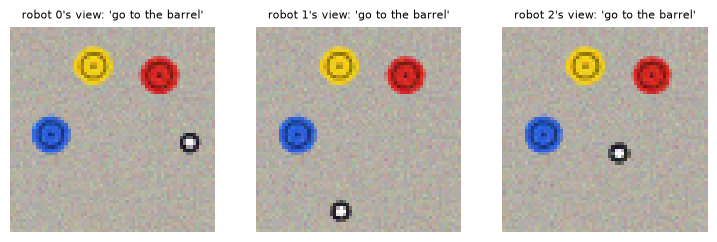

In [2]:
def team_episode(seed, n=3):
    r = random.Random(seed)
    kind = r.choice(scenes.KINDS)
    scene = scenes.random_scene(r, n_objects=n, min_dist=0.32, kinds=(kind,))
    starts = []
    while len(starts) < n:
        p = np.array([r.uniform(0.08, 0.92), r.uniform(0.08, 0.92)])
        if all(np.hypot(*(p - [o.x, o.y])) > 0.3 for o in scene.objects) and all(np.linalg.norm(p - q) > 0.15 for q in starts):
            starts.append(p)
    return kind, scene, np.array(starts)


def robots_for(scene, starts, instructions, targets):
    """One DepotNav per robot sharing the scene; each renders only itself."""
    envs = []
    for p, ins, tg in zip(starts, instructions, targets):
        e = DepotNav()
        e.reset(seed=0)
        e.scene, e.p, e.t, e.instruction, e.targets = scene, p.copy(), 0, ins, tg
        envs.append(e)
    return envs


kind, scene, starts = team_episode(7)
envs = robots_for(scene, starts, [f"go to the {kind}"] * 3, [list(scene.objects)] * 3)
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for k, (ax, e) in enumerate(zip(axs, envs)):
    ax.imshow(e.obs()["image"]); ax.set_title(f"robot {k}'s view: '{e.instruction}'", fontsize=8); ax.axis("off")
plt.show()

## 2. Running a team
`run_teams` steps many team episodes in lockstep, querying the VLA in one batch for every robot that needs a
new chunk (4 actions executed per chunk, as in Lab 11). Optionally a CBF filter keeps robots `sep` apart.

In [3]:
@torch.no_grad()
def run_teams(teams, sep=None, max_steps=50):
    """teams: list of lists of DepotNav (one list per team episode). Returns per-team metrics."""
    flat = [e for t in teams for e in t]
    ins = pad_instructions([encode_instruction(e.instruction) for e in flat], 5)
    queue = [[] for _ in flat]
    done = np.zeros(len(flat), bool)
    min_gap = np.full(len(teams), np.inf)
    owner = np.cumsum([0] + [len(t) for t in teams])
    for step in range(max_steps):
        need = [k for k, e in enumerate(flat) if not done[k] and not queue[k]]
        if need:
            obs = [flat[k].obs() for k in need]
            chunks = vla.act(to_tensor(np.stack([o["image"] for o in obs])).to(dev), torch.as_tensor(ins[need]).to(dev),
                             torch.as_tensor(np.stack([o["state"] for o in obs])).to(dev)).cpu().numpy()
            for j, k in enumerate(need):
                queue[k] = list(chunks[j][:4])
        for ti, t in enumerate(teams):
            for r, e in enumerate(t):
                k = owner[ti] + r
                if done[k]:
                    continue
                a = queue[k].pop(0)
                if sep is not None:
                    u, _ = cbf_filter(e.p, a * e.v_step / 0.1, others=[o.p for o in t if o is not e], sep=sep,
                                      alpha=3.0, u_max=e.v_step / 0.1)
                    a = u / (e.v_step / 0.1)
                _, d, _ = e.step(a)
                done[k] = d
            ps = np.array([e.p for e in t])
            gaps = [np.linalg.norm(ps[i] - ps[j]) for i in range(len(t)) for j in range(i + 1, len(t))]
            min_gap[ti] = min(min_gap[ti], min(gaps))
        if done.all():
            break
    out = []
    for ti, t in enumerate(teams):
        objs = t[0].scene.objects
        reached = [min(range(len(objs)), key=lambda j: np.hypot(*(e.p - [objs[j].x, objs[j].y])))
                   if e.distance_to_targets() < e.success_radius else None for e in t]
        got = {j for j in reached if j is not None}
        out.append(dict(success=len(got) == len(objs), covered=len(got), duplicates=sum(j is not None for j in reached) - len(got),
                        steps=max(e.t for e in t), min_gap=min_gap[ti]))
    return out


def summary(label, res):
    s = np.array([r["success"] for r in res])
    lo, hi = wilson(s.sum(), len(s))
    print(f"{label:44s} team success {s.mean():.2f} [{lo:.2f}, {hi:.2f}]  objects covered "
          f"{np.mean([r['covered'] for r in res]):.2f}/3  duplicated {np.mean([r['duplicates'] for r in res]):.2f}  "
          f"makespan {np.mean([r['steps'] for r in res]):.1f} steps  min gap {np.mean([r['min_gap'] for r in res]):.3f}")


def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, c - h), min(1.0, c + h)


SEEDS = range(40_000, 40_200)
EPISODES = [team_episode(s) for s in SEEDS]

## 3. Independent VLAs
Every robot receives the team instruction as it stands — *"go to the crate"* — the kind-only, ambiguous
instruction the VLA was trained to follow (any matching object counts). Nothing tells the robots apart.

In [4]:
indep = run_teams([robots_for(sc, st, [f"go to the {k}"] * 3, [list(sc.objects)] * 3) for k, sc, st in EPISODES])
summary("independent: 'go to the <kind>' x 3", indep)
print(f"if each robot picked a crate uniformly at random: team success {math.factorial(3) / 3 ** 3:.2f}")

independent: 'go to the <kind>' x 3          team success 0.02 [0.01, 0.05]  objects covered 1.39/3  duplicated 1.06  makespan 32.0 steps  min gap 0.039
if each robot picked a crate uniformly at random: team success 0.22


Each robot follows the instruction it was given — "go to *a* crate" — yet the team almost never succeeds. The
duplicates column shows why: the VLA's choice among matching objects is far from uniform, and robots in the same
scene tend to pick the *same* crate, so the team does even worse than random choice would. (Exercise: find what
the choice depends on.) Independence is the problem (book 14.1), not the policy.

## 4. Centralised allocation
A central allocator knows the robots' positions and the objects' (from a shared map or a detector) and solves
the assignment with travel distance as cost; each robot then receives an unambiguous instruction for its own
object. Greedy vs the optimal auction:

In [5]:
def allocated(method):
    teams, extra = [], []
    for kind, sc, st in EPISODES:
        objs = sc.objects
        cost = np.array([[np.hypot(*(p - [o.x, o.y])) for o in objs] for p in st])
        task = greedy(cost) if method == "greedy" else auction(cost)[0]
        extra.append((total(cost, task), total(cost, task, makespan=True)))
        teams.append(robots_for(sc, st, [f"go to the {objs[j].color} {objs[j].kind}" for j in task],
                                [[objs[j]] for j in task]))
    return teams, np.array(extra)


for method in ("greedy", "auction"):
    teams, extra = allocated(method)
    res = run_teams(teams)
    summary(f"centralised {method}", res)
    print(f"{'':44s} planned travel: total {extra[:, 0].mean():.3f}, longest trip {extra[:, 1].mean():.3f}")

centralised greedy                           team success 0.95 [0.91, 0.97]  objects covered 2.95/3  duplicated 0.00  makespan 17.6 steps  min gap 0.213
                                             planned travel: total 1.360, longest trip 0.633


centralised auction                          team success 0.95 [0.92, 0.98]  objects covered 2.96/3  duplicated 0.00  makespan 15.3 steps  min gap 0.256
                                             planned travel: total 1.282, longest trip 0.533


Allocation removes duplicates by construction; remaining failures are the VLA's own (an unambiguous
instruction it does not execute correctly). The auction's optimal assignments shorten total travel relative to
greedy — a few percent on random instances, more on unlucky ones (book 14.4).

## 5. Decentralised auction over a lossy radio
No central computer: each robot knows its own distance to each object and runs the auction with its local view
of prices, exchanging bids over a broadcast channel that drops messages. Two variants: bids sent once, and
claims re-broadcast every round (as CBBA does).

rebroadcast False loss 0.0: conflicting assignments 0.00, messages per allocation    9.7
rebroadcast False loss 0.2: conflicting assignments 0.25, messages per allocation    8.6
rebroadcast False loss 0.5: conflicting assignments 0.56, messages per allocation    7.3
rebroadcast False loss 0.8: conflicting assignments 0.73, messages per allocation    6.4
rebroadcast True  loss 0.0: conflicting assignments 0.00, messages per allocation  180.0


rebroadcast True  loss 0.2: conflicting assignments 0.00, messages per allocation  180.0


rebroadcast True  loss 0.5: conflicting assignments 0.00, messages per allocation  180.0
rebroadcast True  loss 0.8: conflicting assignments 0.08, messages per allocation  180.0


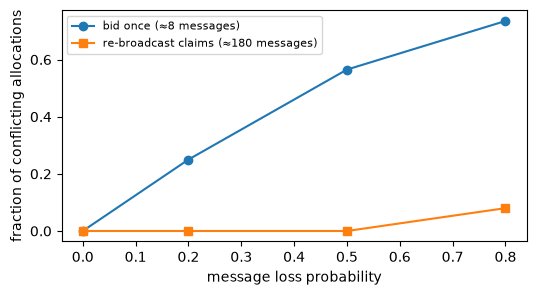

In [6]:
rng = np.random.default_rng(0)
rows = []
for rebroadcast in (False, True):
    for p_loss in (0.0, 0.2, 0.5, 0.8):
        conflicts, msgs = 0, 0
        for e_i, (kind, sc, st) in enumerate(EPISODES):
            cost = np.array([[np.hypot(*(p - [o.x, o.y])) for o in sc.objects] for p in st])
            mine, sent = decentralised_auction(cost, LossyChannel(3, p_loss=p_loss, seed=e_i), st, rounds=30,
                                               rebroadcast=rebroadcast)
            conflicts += len(set(mine)) < 3
            msgs += sent
        rows.append((rebroadcast, p_loss, conflicts / len(EPISODES), msgs / len(EPISODES)))
        print(f"rebroadcast {str(rebroadcast):5s} loss {p_loss:.1f}: conflicting assignments {conflicts / len(EPISODES):.2f}, "
              f"messages per allocation {msgs / len(EPISODES):6.1f}")

fig, ax = plt.subplots(figsize=(6, 3))
for rb, mk in ((False, "o-"), (True, "s-")):
    r_ = [r for r in rows if r[0] == rb]
    ax.plot([r[1] for r in r_], [r[2] for r in r_], mk, label=f"{'re-broadcast claims' if rb else 'bid once'} "
            f"(≈{np.mean([r[3] for r in r_]):.0f} messages)")
ax.set_xlabel("message loss probability"); ax.set_ylabel("fraction of conflicting allocations")
ax.legend(fontsize=8); plt.show()

Bidding once is cheap but fragile: a lost bid leaves two robots each believing they won. Re-broadcasting
claims makes the auction robust to heavy loss at roughly twenty times the messages — the
expressiveness/robustness/bandwidth trade-off of book 14.2 in miniature. With the conflicts that remain, the
team executes as in §3, with duplicated objects.

## 6. Keeping robots apart: safety is not coordination
The VLAs do not see each other, and in §3 independent robots converged on the same object — physically, a
pile-up. A CBF separation constraint between every pair (book 12.4; each robot takes half the effort) keeps a
minimum gap. Does it also fix the team's task?

In [7]:
make_indep = lambda: [robots_for(sc, st, [f"go to the {k}"] * 3, [list(sc.objects)] * 3) for k, sc, st in EPISODES]  # noqa: E731
res_sep = run_teams(make_indep(), sep=0.1)
summary("independent, no separation", indep)
summary("independent, CBF separation 0.10", res_sep)
close = lambda rs: np.mean([r["min_gap"] < 0.1 for r in rs])  # noqa: E731
print(f"episodes with two robots closer than 0.10: {close(indep):.2f} without, {close(res_sep):.2f} with separation")

independent, no separation                   team success 0.02 [0.01, 0.05]  objects covered 1.39/3  duplicated 1.06  makespan 32.0 steps  min gap 0.039
independent, CBF separation 0.10             team success 0.03 [0.01, 0.06]  objects covered 1.49/3  duplicated 0.30  makespan 47.3 steps  min gap 0.117
episodes with two robots closer than 0.10: 0.90 without, 0.01 with separation


The filter removes the near-collisions — robots now queue around the same crate instead of piling onto it —
but the team task still fails: separation is a safety constraint, not a decision about who does what.
Coordination needs allocation (§4–5) or policies that model their teammates (exercise 5).


## Exercises
1. **Makespan.** Allocate with a bottleneck (minimise the longest trip) objective by brute force
   (`vlacourse.teams.brute_force` on a modified cost). How do makespan and total travel change?
2. **Heterogeneous team.** Mark one robot as unable to reach objects in the left half (infinite cost). Which
   allocators handle it, and what happens with independent VLAs?
3. **Language as the message.** Instead of allocating centrally, let robots announce "I take the blue crate"
   over the lossy channel in turn and give later robots the instruction for an unclaimed crate. Compare with §5.
4. **Stop re-broadcasting.** Let robots stop re-broadcasting after their claim has been stable for $k$ rounds.
   Plot conflicts and messages against $k$.
5. **Research question.** Train the toy VLA with an extra input token encoding the positions of teammates, on
   team demonstrations where robots pick distinct targets. Does it learn to avoid duplicates without an
   allocator (book 14.6)?